# Plotting with Matplotlib

**Lecture 7 · Learning Python at the University of Glasgow**

*Khiem Nguyen, University of Glasgow*

> Visualising data and functions with Matplotlib: line plots, styles and labels, figures and axes, subplots, bar charts, scatter plots, histograms, dates, piecewise functions and saving figures for reports.

> **📝 Learning objectives**
>
> By the end of this lecture, you should be able to:
>
> - plot functions and data with `matplotlib.pyplot`, using NumPy arrays from Lecture 6;
> - customise line styles, markers, colours, labels, titles, legends, grids and axis limits;
> - explain the difference between a *Figure* and an *Axes*, and use the object-oriented interface `fig, ax = plt.subplots()`;
> - arrange several plots in one figure with subplots;
> - create bar charts, scatter plots, histograms, filled areas and plots with dates;
> - plot piecewise functions without loops, using `np.where()`;
> - save figures in formats suitable for reports.

# Introduction

## What is Matplotlib?

**Matplotlib** is a comprehensive library for creating static, animated and interactive visualisations in Python. In the words of its developers, Matplotlib makes easy things easy and hard things possible. With it, you can

- create publication-quality plots;
- make interactive figures that can zoom, pan and update;
- customise the visual style and layout;
- export to many file formats;
- embed figures in JupyterLab and in graphical user interfaces;
- use a rich array of third-party packages built on Matplotlib.

## The `pyplot` module

`matplotlib.pyplot` is a collection of functions that make Matplotlib work like MATLAB. Each `pyplot` function makes some change to a figure: it creates a figure, creates a plotting area in a figure, plots some lines in a plotting area, decorates the plot with labels, and so on.

`pyplot` keeps track of the *current* figure and the *current* plotting area, and directs every plotting command to them. By the community's convention, it is always imported under the name `plt`. We also import NumPy, which we use to generate the data.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

> **💡 Displaying plots: `plt.show()`**
>
> In Jupyter, a plot is displayed automatically at the end of the cell that creates it. Calling `plt.show()` at the end of the cell finishes the figure explicitly and, as a bonus, stops Jupyter from also printing the value returned by the last plotting command, such as `[<matplotlib.lines.Line2D at 0x...>]`. (Ending the last line with a semicolon `;` has the same effect.) In a plain Python script, `plt.show()` is essential: it opens the window that displays the figure.

# First plots

## Plotting a function $y = f(x)$

The function `plt.plot(x, y)` draws straight lines between the points $(x_1, y_1), (x_2, y_2), \ldots$, where `x` and `y` are two lists or arrays of the same length. Let us plot $f(x) = \frac{1}{2} x$, first with Python lists:

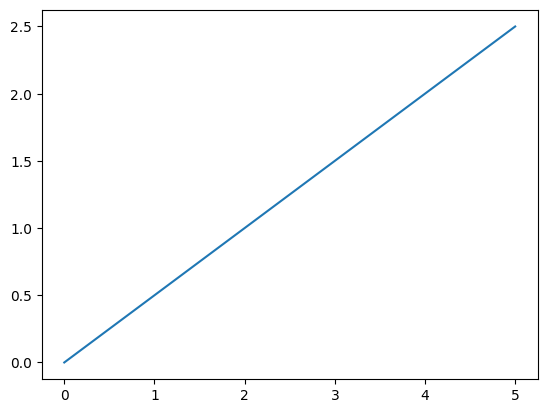

In [2]:
x = list(range(6))                  # 0, 1, 2, 3, 4, 5
y = [0.5 * value for value in x]    # a list comprehension (Lecture 6)
plt.plot(x, y)
plt.show()

Now $g(x) = x^2$ at the integers from $-5$ to $5$:

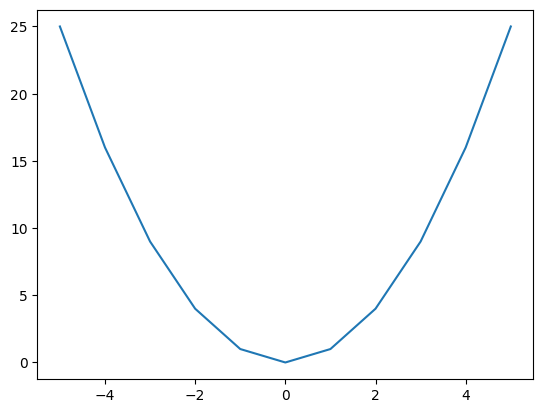

In [3]:
x = list(range(-5, 6))
y = [value ** 2 for value in x]
plt.plot(x, y)
plt.show()

The graph looks jagged, because the points are far apart and `plot()` joins them with straight lines. With NumPy, we can use as many points as we like — and compute the values of the function without any loop:

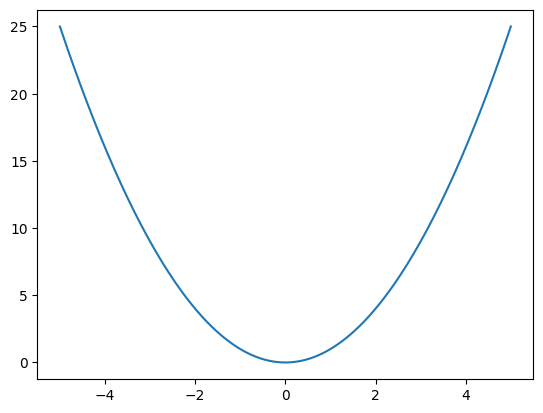

In [4]:
x = np.linspace(-5, 5, 201)    # 201 points from -5 to 5
plt.plot(x, x**2)
plt.show()

Here is $h(x) = e^x$. This time we omit `plt.show()`, so Jupyter also prints the list of line objects returned by `plt.plot()`:

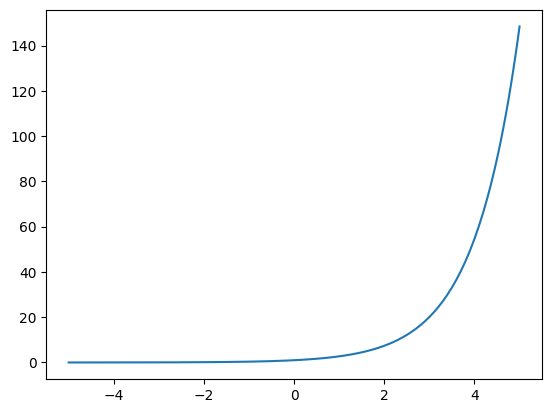

In [5]:
x = np.linspace(-5, 5, 201)
plt.plot(x, np.exp(x))

## Several curves in one plot

Every call to `plt.plot()` adds a curve to the current plotting area, until the figure is finished with `plt.show()` (or at the end of the cell). Matplotlib picks a different colour for each curve automatically.

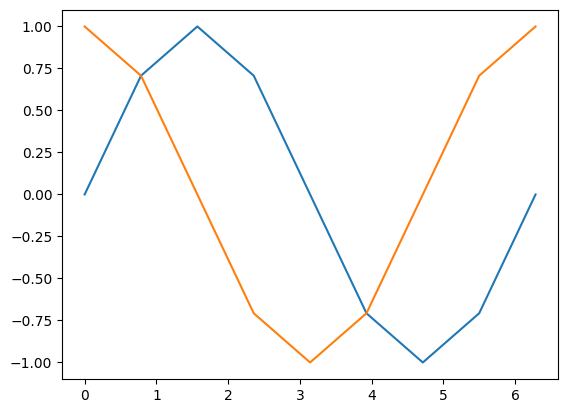

In [6]:
x = np.linspace(0.0, 2*np.pi, 9)     # 9 points: one every 45 degrees
plt.plot(x, np.sin(x))
plt.plot(x, np.cos(x))
plt.show()

With only 9 points, the curves are visibly made of straight segments. Try 100 points instead.

# Customising plots

## Line styles, markers and colours

The appearance of a curve is controlled by keyword arguments:

```python
plt.plot(x, y, keyword1=value1, keyword2=value2, ...)
```

There are far too many keywords to remember them all, and you should not try. Learn the few that you use most often; for the rest, consult the [documentation](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.plot.html).

| Keyword argument | Meaning                                              | Example values                          |
|------------------|------------------------------------------------------|-----------------------------------------|
| `color`          | colour of the line                                   | `"r"`, `"black"`, `"#003865"`, `[0.5, 0.6, 0.2]` |
| `linestyle`      | style of the line                                    | `"-"`, `"--"`, `"-."`, `":"`            |
| `linewidth`      | thickness of the line                                | `2.0`                                   |
| `marker`         | symbol drawn at each data point                      | `"o"`, `"s"`, `"^"`, `"x"`, `"."`       |
| `markersize`     | size of the markers                                  | `8`                                     |
| `alpha`          | transparency, from 0 (invisible) to 1 (opaque)       | `0.5`                                   |
| `label`          | text shown for this curve in the legend              | `"sin(x)"`                              |

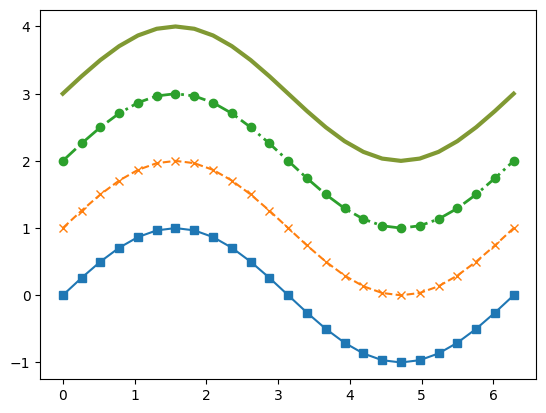

In [7]:
x = np.linspace(0.0, 2*np.pi, 25)
y = np.sin(x)

plt.plot(x, y, marker="s")                         # square markers
plt.plot(x, y + 1, linestyle="--", marker="x")     # dashed line with crosses
plt.plot(x, y + 2, linestyle="-.", marker="o", linewidth=2.0)
plt.plot(x, y + 3, color=[0.5, 0.6, 0.2], linewidth=3.0)   # an RGB colour
plt.show()

Colours can be given as single letters (`"b"` blue, `"r"` red, `"g"` green, `"k"` black, `"m"` magenta, `"y"` yellow), as names (`"orange"`), as hexadecimal codes (`"#003865"`), or as lists of three numbers between 0 and 1 for the red, green and blue components. For quick plots, a **format string** combines colour, marker and line style in one short argument:

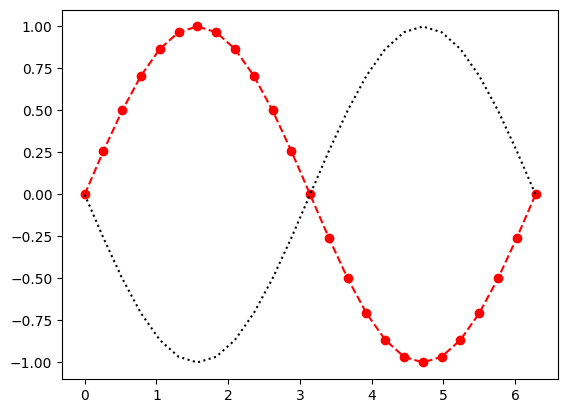

In [8]:
plt.plot(x, y, "r--o")        # red, dashed line, circle markers
plt.plot(x, -y, "k:")         # black, dotted line, no markers
plt.show()

## Labels, title, legend, grid and limits

A plot without labels is only half a plot. Every figure in a report needs axis labels (with units!), and a legend if it shows more than one curve.

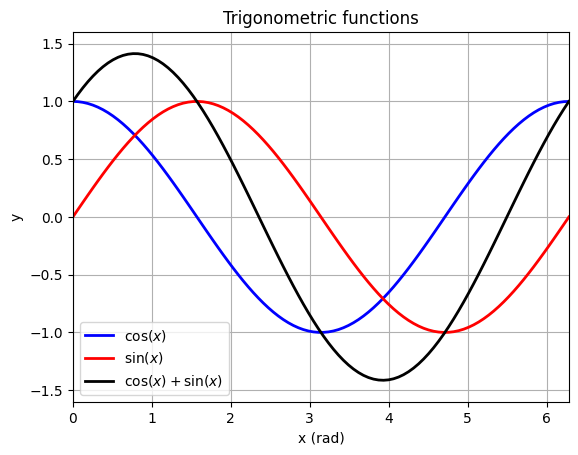

In [9]:
x = np.linspace(0.0, 2*np.pi, 100)
plt.plot(x, np.cos(x), color="b", linewidth=2.0, label=r"$\cos(x)$")
plt.plot(x, np.sin(x), color="r", linewidth=2.0, label=r"$\sin(x)$")
plt.plot(x, np.cos(x) + np.sin(x), color="k", linewidth=2.0, label=r"$\cos(x) + \sin(x)$")
plt.xlabel("x (rad)")
plt.ylabel("y")
plt.title("Trigonometric functions")
plt.legend(loc="lower left")
plt.grid(True)
plt.xlim(0, 2*np.pi)
plt.ylim(-1.6, 1.6)
plt.show()

> **💡 Mathematics in labels**
>
> Text between dollar signs is typeset as mathematics, using LaTeX notation, e.g. `r"$\sin(x)$"` or `r"$\sigma_{xx}$ (MPa)"`. The `r` in front of the string makes it a **raw string**, in which a backslash is an ordinary character rather than the start of an escape sequence such as `\n` (Lecture 1).

# Figures and axes: the object-oriented interface

So far, we have let `pyplot` keep track of the current figure for us. For anything beyond a quick plot, it is clearer to work with the figure and its plotting areas *explicitly*. To do so, we need two terms:

- A **Figure** is the whole canvas — the window or the image file. It can contain one or several plotting areas.
- An **Axes** is one plotting area, with its own x- and y-axes, lines, title, labels and legend. (Note that "Axes" here means a *plotting area*, not the plural of the mathematical term "axis".)

![The anatomy of a Matplotlib figure. A Figure contains one or more Axes; everything inside a plotting area is controlled through the Axes object ax.](figures/matplotlib-anatomy.svg)

**Figure:** The anatomy of a Matplotlib figure. A Figure contains one or more Axes; everything inside a plotting area is controlled through the Axes object `ax`.

The function `plt.subplots()` creates a figure together with its Axes and returns both. We then call the **methods** of the Axes object `ax` instead of the `plt` functions. Most method names are those of the `pyplot` functions with `set_` in front:

| `pyplot` function | Axes method       |
|-------------------|-------------------|
| `plt.plot()`      | `ax.plot()`       |
| `plt.xlabel()`    | `ax.set_xlabel()` |
| `plt.ylabel()`    | `ax.set_ylabel()` |
| `plt.title()`     | `ax.set_title()`  |
| `plt.xlim()`      | `ax.set_xlim()`   |
| `plt.ylim()`      | `ax.set_ylim()`   |
| `plt.legend()`    | `ax.legend()`     |
| `plt.grid()`      | `ax.grid()`       |

Here is the damped oscillation of the figure above, written in the object-oriented style:

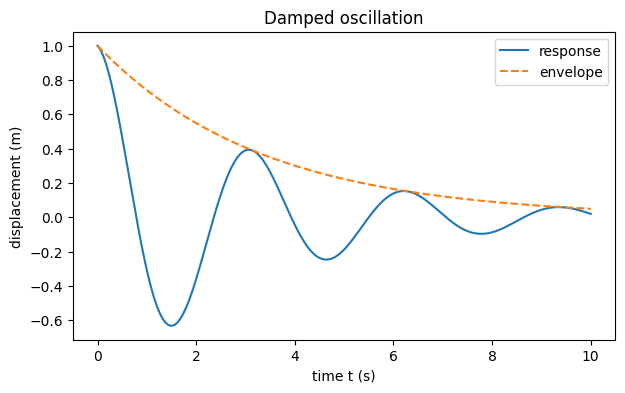

In [10]:
t = np.linspace(0, 10, 500)
envelope = np.exp(-0.3 * t)

fig, ax = plt.subplots(figsize=(7, 4))     # width and height in inches
ax.plot(t, envelope * np.cos(2 * t), label="response")
ax.plot(t, envelope, "--", label="envelope")
ax.set_xlabel("time t (s)")
ax.set_ylabel("displacement (m)")
ax.set_title("Damped oscillation")
ax.legend()
plt.show()

> **❗ Which style should I use?**
>
> Both styles produce the same figures. The `pyplot` style is quick for simple, one-off plots. The object-oriented style is recommended for everything else — in particular for figures with several plots — because it is always clear which plotting area a command acts on. Avoid mixing the two styles in the same figure.

# Several plots in one figure

`plt.subplots(nrows, ncols)` creates a grid of Axes and returns them in an array (Lecture 6), so `axs[0]` is the first plot of a single row or column, and `axs[i, j]` is the plot in row `i` and column `j` of a grid. Useful options include:

- `sharex=True` or `sharey=True`, so that the plots share the same x- or y-axis;
- `figsize=(width, height)`, the size of the figure in inches;
- `layout="constrained"`, which arranges the plots so that their labels do not overlap. (In older versions of Matplotlib, call `fig.tight_layout()` instead.)

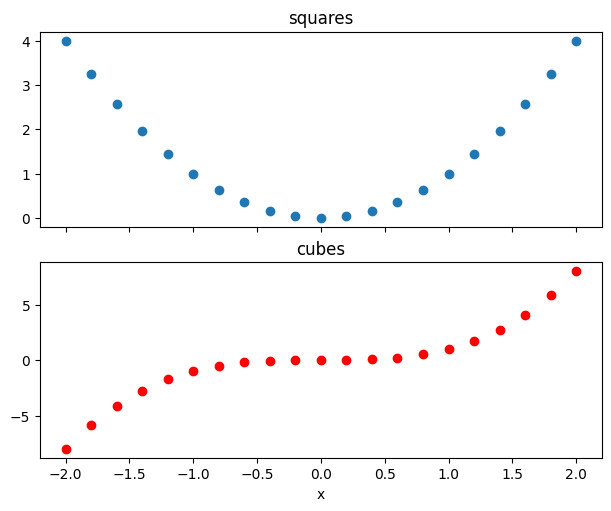

In [11]:
x = np.linspace(-2, 2, 21)

fig, axs = plt.subplots(2, 1, sharex=True, figsize=(6, 5), layout="constrained")
axs[0].scatter(x, x**2)
axs[0].set_title("squares")
axs[1].scatter(x, x**3, color="r")
axs[1].set_title("cubes")
axs[1].set_xlabel("x")          # with sharex=True, one x-label at the bottom is enough
plt.show()

With `sharey=True`, plots side by side use the same vertical scale, which makes them easy to compare:

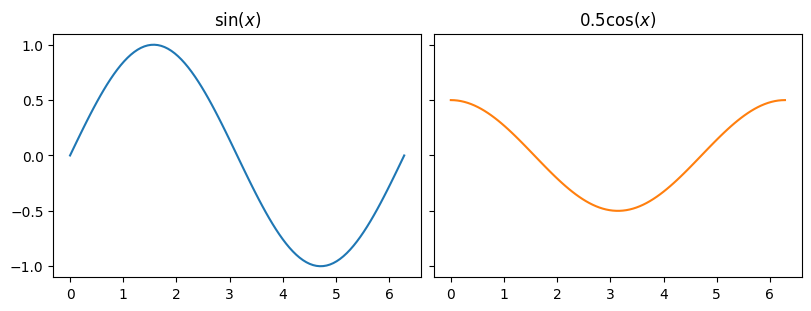

In [12]:
x = np.linspace(0, 2*np.pi, 100)

fig, axs = plt.subplots(1, 2, sharey=True, figsize=(8, 3), layout="constrained")
axs[0].plot(x, np.sin(x))
axs[0].set_title(r"$\sin(x)$")
axs[1].plot(x, 0.5 * np.cos(x), color="C1")    # "C1" is the second default colour
axs[1].set_title(r"$0.5\cos(x)$")
plt.show()

For a grid, a loop over `axs.flat` visits every Axes in turn, and `fig.suptitle()` adds a title for the whole figure:

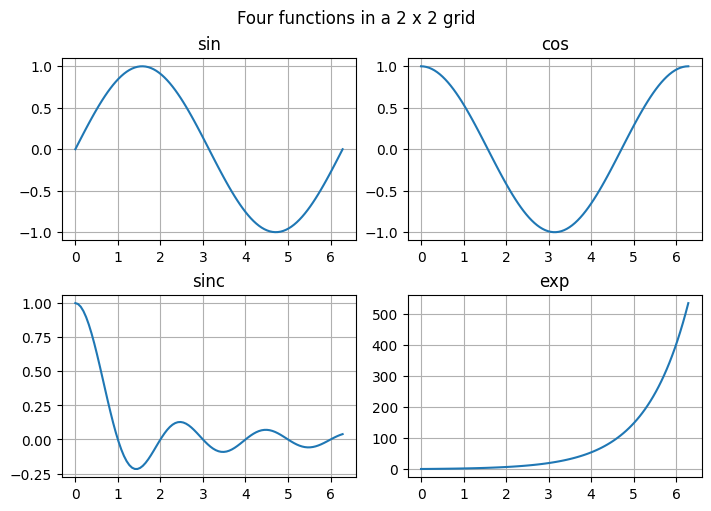

In [13]:
x = np.linspace(0, 2*np.pi, 100)
functions = [np.sin, np.cos, np.sinc, np.exp]
names = ["sin", "cos", "sinc", "exp"]

fig, axs = plt.subplots(2, 2, figsize=(7, 5), layout="constrained")
for ax, f, name in zip(axs.flat, functions, names):    # zip(): Lecture 3
    ax.plot(x, f(x))
    ax.set_title(name)
    ax.grid(True)
fig.suptitle("Four functions in a 2 x 2 grid")
plt.show()

# Other types of plots

## Bar charts

When we report a small number of discrete values — monthly sales, the energy use of different buildings, or the rainfall in each month — a **bar chart** is often the best choice. The following example shows the rainfall (in cm) from January to May.

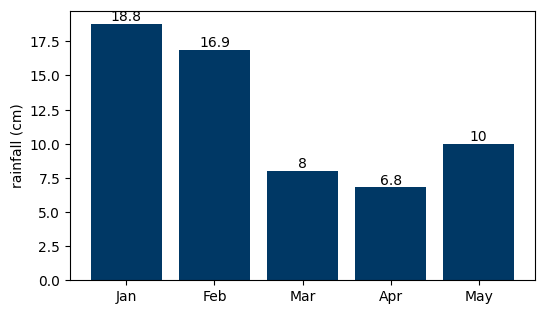

In [14]:
months = ["Jan", "Feb", "Mar", "Apr", "May"]
rain = [18.8, 16.9, 8.0, 6.8, 10.0]

fig, ax = plt.subplots(figsize=(6, 3.5))
bars = ax.bar(months, rain, color="#003865")
ax.bar_label(bars)                  # write the value on top of each bar
ax.set_ylabel("rainfall (cm)")
plt.show()

## Scatter plots

To show individual data points $\{(x_1, y_1), (x_2, y_2), \ldots, (x_N, y_N)\}$ without joining them with lines, use a **scatter plot**, `plt.scatter()` or `ax.scatter()`. The keyword argument `s` sets the size of the markers.

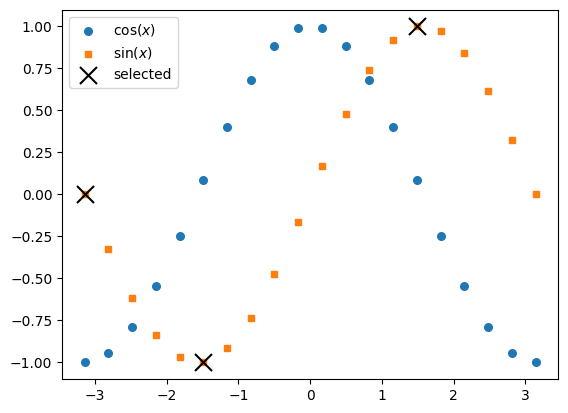

In [15]:
x = np.linspace(-np.pi, np.pi, 20)

fig, ax = plt.subplots()
ax.scatter(x, np.cos(x), s=30, label=r"$\cos(x)$")
ax.scatter(x, np.sin(x), marker="s", s=20, label=r"$\sin(x)$")

# Highlight a few points, selected with a list of indices (Lecture 6)
x_sub = x[[0, 5, 14]]
ax.scatter(x_sub, np.sin(x_sub), s=150, marker="x", color="k", label="selected")
ax.legend()
plt.show()

## Histograms

A **histogram** shows how measured values are distributed: it divides the range of the data into intervals (*bins*) and draws one bar per bin, whose height is the number of values in it. Here are 1000 simulated measurements of a length, normally distributed with a mean of 50 mm and a standard deviation of 2 mm (random numbers: Lecture 6).

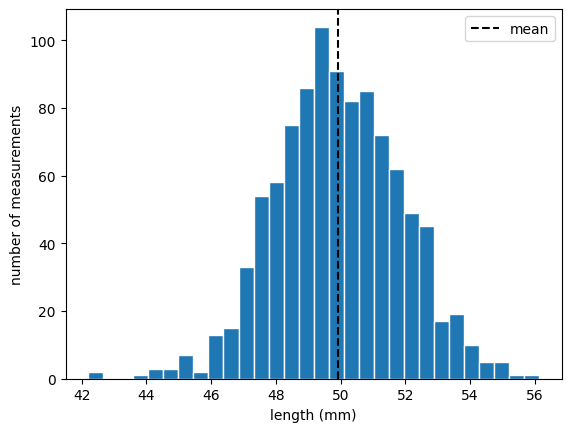

In [16]:
rng = np.random.default_rng(seed=0)
lengths = rng.normal(loc=50.0, scale=2.0, size=1000)

fig, ax = plt.subplots()
ax.hist(lengths, bins=30, edgecolor="white")
ax.axvline(lengths.mean(), color="k", linestyle="--", label="mean")   # a vertical line
ax.set_xlabel("length (mm)")
ax.set_ylabel("number of measurements")
ax.legend()
plt.show()

## Filling the area between two curves

`fill_between(x, y1, y2)` shades the area between two curves. The keyword argument `where` restricts the shading to the region where a condition holds, written as a Boolean mask (Lecture 6).

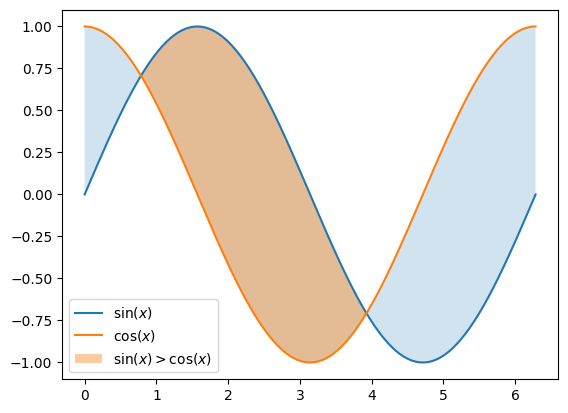

In [17]:
x = np.linspace(0, 2*np.pi, 200)
y1 = np.sin(x)
y2 = np.cos(x)

fig, ax = plt.subplots()
ax.plot(x, y1, label=r"$\sin(x)$")
ax.plot(x, y2, label=r"$\cos(x)$")
ax.fill_between(x, y1, y2, alpha=0.2)                              # all the area between
ax.fill_between(x, y1, y2, where=(y1 > y2), alpha=0.4, label=r"$\sin(x) > \cos(x)$")
ax.legend()
plt.show()

## Plotting dates and times

Measurements are often recorded at particular dates and times. Python's `datetime` module represents them as `datetime` objects. Two methods convert between `datetime` objects and strings, using the format codes in the table below:

- `datetime.strptime(text, format)` *parses* a string into a `datetime` object;
- `my_date.strftime(format)` *formats* a `datetime` object as a string.

| Code | Meaning                                   | Code | Meaning                             |
|------|-------------------------------------------|------|-------------------------------------|
| `%A` | weekday name, e.g. Monday                 | `%H` | hour, 24-hour clock (00 to 23)      |
| `%B` | month name, e.g. January                  | `%I` | hour, 12-hour clock (01 to 12)      |
| `%b` | abbreviated month name, e.g. Jan          | `%p` | AM or PM                            |
| `%m` | month as a number (01 to 12)              | `%M` | minutes (00 to 59)                  |
| `%d` | day of the month (01 to 31)               | `%S` | seconds (00 to 59)                  |
| `%Y` | four-digit year, e.g. 2024                | `%y` | two-digit year, e.g. 24             |

In [18]:
from datetime import datetime

new_year = datetime.strptime("1/1/2022", "%m/%d/%Y")   # string -> datetime
print(new_year)
print(new_year.strftime("%B %d %Y"))                    # datetime -> string
print(new_year.strftime("%d/%m/%y"))
print(new_year.strftime("%A %d %B %Y"))

2022-01-01 00:00:00
January 01 2022
01/01/22
Saturday 01 January 2022


Matplotlib accepts lists of `datetime` objects directly as coordinates. The submodule `matplotlib.dates` controls how the dates are written on the axis, and `fig.autofmt_xdate()` rotates the labels so that they do not overlap. Notice that the axis is a genuine *time* axis: there are gaps where there are no measurements (24 and 25 June).

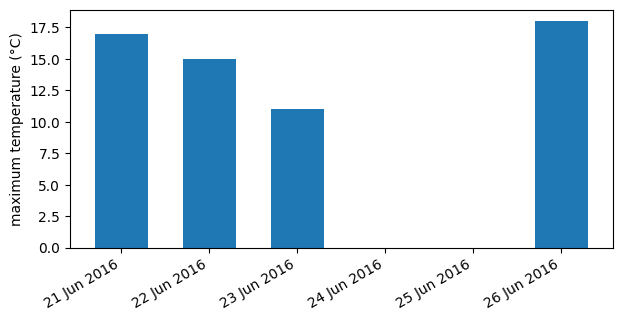

In [19]:
import matplotlib.dates as mdates

dates = [datetime(2016, 6, 21), datetime(2016, 6, 22),
         datetime(2016, 6, 23), datetime(2016, 6, 26)]
highs = [17, 15, 11, 18]

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(dates, highs, width=0.6)
ax.set_ylabel("maximum temperature (°C)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b %Y"))
fig.autofmt_xdate()
plt.show()

# Plotting piecewise functions

Some functions are defined piece by piece, and plotting them needs a little care. A classic example from structural engineering is the bending moment in a simply supported beam of length $L$ with a point load $P$ at mid-span:

$$
M(x) =
\begin{cases}
\dfrac{P x}{2}, & 0 \leq x \leq \dfrac{L}{2}, \\[2ex]
\dfrac{P (L - x)}{2}, & \dfrac{L}{2} < x \leq L.
\end{cases}
$$

The bending moment diagram is V-shaped, with its maximum $PL/4$ at mid-span. (Here, sagging moments are positive. Some textbooks draw bending moments on the tension side of the beam, which flips the sign.) A natural first attempt uses an `if` statement:

In [20]:
def bending_moment(x, length, load):
    if x <= length / 2:
        return load * x / 2
    else:
        return load * (length - x) / 2

This works perfectly for a single number, but fails for an array:

In [21]:
length, load = 10.0, 2.0                 # m and kN
x = np.linspace(0, length, 201)
M = bending_moment(x, length, load)

ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()

The reason is that `x <= length / 2` is now a Boolean **array** (Lecture 6), with one value per point, whereas `if` needs a single `True` or `False`. There are two remedies.

**Remedy 1: `np.vectorize()`.** This wraps our function so that it is called once for each element of the array. It is convenient, but it is only a loop in disguise, so it is no faster than a `for` loop.

In [22]:
bending_moment_vec = np.vectorize(bending_moment)
M = bending_moment_vec(x, length, load)
print(M.max())

5.0


**Remedy 2: `np.where()` (recommended).** The function `np.where(condition, a, b)` builds an array that takes the values of `a` where the condition is `True` and the values of `b` elsewhere. It is fully vectorised and therefore fast.

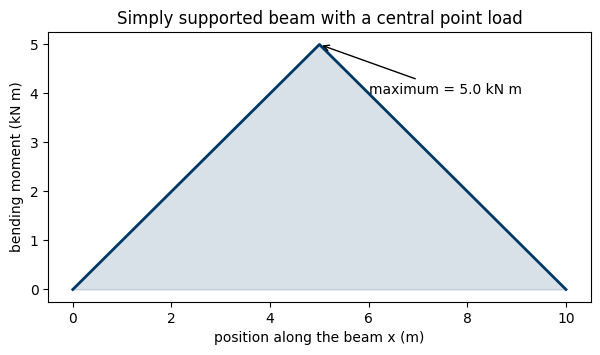

In [23]:
M = np.where(x <= length / 2, load * x / 2, load * (length - x) / 2)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(x, M, color="#003865", linewidth=2)
ax.fill_between(x, M, alpha=0.15, color="#003865")
ax.annotate(f"maximum = {M.max():.1f} kN m",
            xy=(length / 2, M.max()), xytext=(length / 2 + 1.0, M.max() - 1.0),
            arrowprops=dict(arrowstyle="->"))
ax.set_xlabel("position along the beam x (m)")
ax.set_ylabel("bending moment (kN m)")
ax.set_title("Simply supported beam with a central point load")
plt.show()

# Saving figures

To use a figure in a report, save it to a file with `fig.savefig()` (or `plt.savefig()` in the `pyplot` style). The file format follows from the extension of the file name:

In [ ]:
fig.savefig("bending_moment.pdf")                               # vector graphics
fig.savefig("bending_moment.png", dpi=300, bbox_inches="tight")  # high-resolution image

- **Vector formats** (`.pdf`, `.svg`) stay sharp at any zoom level and are ideal for reports written in LaTeX or Word.
- **Raster formats** (`.png`, `.jpg`) consist of pixels; choose a high resolution with `dpi=300` for printing.
- `bbox_inches="tight"` trims the empty margin around the figure.

> **⚠️ Save before you show**
>
> In the `pyplot` style, call `plt.savefig()` *before* `plt.show()`. In a script, `plt.show()` may close the figure, and saving afterwards would produce an empty image.

# Summary

- `import matplotlib.pyplot as plt` gives the MATLAB-like `pyplot` interface; `plt.plot(x, y)` joins the points with lines, and NumPy arrays from `np.linspace()` give smooth curves.
- Customise curves with `color`, `linestyle`, `linewidth`, `marker`, `markersize`, `alpha` and `label`, or with a format string such as `"r--o"`. Always label the axes, with units.
- A **Figure** is the whole canvas and an **Axes** is one plotting area. `fig, ax = plt.subplots()` gives explicit control and is the recommended style; `plt.subplots(nrows, ncols)` creates a grid of Axes.
- `bar()`, `scatter()`, `hist()` and `fill_between()` create other common types of plots; `datetime` objects can be plotted directly on a time axis.
- Plot piecewise functions with `np.where()` rather than `if` statements.
- Save figures with `fig.savefig()`: vector formats for reports, PNG with a high `dpi` for images.

# Exercises

## Exercise 1: Reproduce the anatomy figure

Reproduce the figure in the section on figures and axes as closely as you can: plot the damped oscillation $y(t) = e^{-0.3t}\cos(2t)$ and its envelope for $0 \le t \le 10$, with a title, axis labels, a legend and a grid. Add the lower envelope $-e^{-0.3t}$ in the same style as the upper one, and save the figure as a PDF file.

## Exercise 2: Projectile trajectories

Using your results from Exercise 4 of Lecture 6, plot the trajectories $y$ versus $x = v_0 \cos\theta \, t$ of the five projectiles in one Axes. Label each curve with its launch angle in the legend, e.g. `label=f"{angle} deg"`, and show only the part above the ground, for example with `ax.set_ylim(bottom=0)`. Which angle gives the longest range?

## Exercise 3: Shear force and bending moment diagrams

For the simply supported beam with a central point load (length $L = 10$ m, load $P = 2$ kN), the shear force is $V(x) = P/2$ for $x < L/2$ and $V(x) = -P/2$ for $x > L/2$. Create a figure with two Axes, one above the other, sharing the x-axis: the shear force diagram on top and the bending moment diagram below. Use `np.where()` for both, shade the areas with `fill_between()`, and mark the maximum bending moment with `annotate()`.

## Exercise 4: Distribution of measurements

Generate 1000 simulated measurements with `rng.normal(loc=50.0, scale=5.0, size=1000)`. Plot a histogram with 30 bins, and draw vertical lines at the mean (solid) and at the mean plus and minus one standard deviation (dashed), with a legend. Then compute the fraction of measurements that lie within one standard deviation of the mean. Is it close to the theoretical value of about 68%?

## Exercise 5: A small dashboard

Create a $2 \times 2$ grid of plots with a common title (`fig.suptitle()`) showing:

1. $\tan(x)$ for $-\pi < x < \pi$, with the y-axis limited to $[-5, 5]$ — what happens near $x = \pm\pi/2$, and why?
2. a bar chart of the monthly rainfall from the section on bar charts;
3. a scatter plot of 50 random points $(x, y)$ with $x$ and $y$ drawn from `rng.random(50)`;
4. a filled area between $\sin(x)$ and $\sin(2x)$.

# Further reading

- [Quick start guide](https://matplotlib.org/stable/users/explain/quick_start.html), from the official Matplotlib documentation.
- The Matplotlib [gallery](https://matplotlib.org/stable/gallery/index.html): hundreds of examples, each with its source code — find a plot that looks like what you need, and adapt it.
- [Customising Matplotlib with style sheets](https://matplotlib.org/stable/users/explain/customizing.html).